# 05 — Forecast Evaluation and the Connection to Hyperledger Fabric

**Purpose:** evaluate the stored FB-FC-v1 forecasts in depth, and then answer the project question for this
component: *can these forecasts support better Fabric configuration decisions?*

**Inputs (all stored):**
- the forecast files in `Flashbots/results/FB-FC-v1/final/`;
- the evaluation tables in `Flashbots/evaluation/FB-FC-v1/`;
- the stored law-implied value-of-information analysis in
  `experiments/results/flashbots_horizon_benchmark_v2/voi/`.

No model is refitted, and the notebook writes no files.

## Setup

In [1]:
from pathlib import Path
import sys, json

ROOT = Path.cwd()
while not (ROOT / "Flashbots" / "fbcommon.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FB = ROOT / "Flashbots"
for sub in ("", "forecasting", "evaluation", "time_series", "data_audit", "preprocessing"):
    sys.path.insert(0, str(FB / sub))

import numpy as np
import pandas as pd
import fbcommon as fc
fc.plot_style()
%matplotlib inline
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.0f}" if abs(v) >= 1e4 else f"{v:.4g}")
print("repository:", ROOT)
print({k: v for k, v in fc.environment().items() if k != "platform"})

repository: C:\OJT_SEM3\AI-Assisted-Permissioned-Blockchain-Architecture-


{'python': '3.14.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit_learn': '1.9.1', 'matplotlib': '3.11.2', 'pyyaml': '6.0.3'}


In [2]:
import metrics as em
RES = FB / "results" / "FB-FC-v1"
EV = FB / "evaluation" / "FB-FC-v1"
FROZEN = json.loads((RES / "select" / "selection_frozen.json").read_text(encoding="utf-8"))
SEL = {(s["target"], s["horizon_s"]): s["selected_model"] for s in FROZEN["selection"].values()}
load = lambda target, H: pd.read_csv(RES / "final" / f"forecasts_F_{target}_H{H}.csv")
COLORS = {"persistence_interval": fc.SERIES[0], "ewma": fc.SERIES[1], "ridge_ar": fc.SERIES[2], "rolling_mean_900": fc.SERIES[3],
          "expanding_mean": fc.SERIES[6], "tod_profile_0921": fc.SERIES[7], "rolling_mean_60": fc.SERIES[5]}

## 1. Metrics and how zeros are handled

Error = forecast - observed.

| Metric | Definition | Zero handling |
|---|---|---|
| MAE (primary) | mean abs e | none needed |
| RMSE | sqrt(mean e^2) | none needed |
| Bias | mean e (> 0 = over-forecast) | none needed |
| WAPE | sum abs e / sum y | NaN only if every y = 0 |
| sMAPE | mean 2 abs e / (abs y + abs yhat) | 0/0 counted as 0 |
| MAPE | mean abs e / y | over y > 0 only; excluded count reported |
| Skill | 1 - MAE / MAE(naive) | none needed |

In [3]:
y, yhat = np.array([0.0, 0.0, 4.0, 10.0]), np.array([0.0, 1.0, 2.0, 11.0])
em.all_metrics(y, yhat)

{'n': 4,
 'mae': 1.0,
 'rmse': 1.224744871391589,
 'bias': 0.0,
 'wape_pct': 28.571428571428573,
 'smape_pct': 69.04761904761905,
 'mape_pct_y_gt_0': 30.0,
 'mape_zero_obs_excluded': 2}

## 2. Selected model vs naive by horizon (test day 12 Oct)

In [4]:
ht = pd.read_csv(EV / "horizon_table.csv")
ht[ht.role != "best_F_in_hindsight"][["target", "unit", "horizon_s", "role", "model", "mae_F", "rmse_F", "bias_F", "smape_pct_F",
                                       "wape_pct_F", "skill_mae_vs_persistence_F", "mae_V", "dm_p_holm_selected_vs_persistence"]]

,target,unit,horizon_s,role,model,mae_F,rmse_F,bias_F,smape_pct_F,wape_pct_F,skill_mae_vs_persistence_F,mae_V,dm_p_holm_selected_vs_persistence
0,arrival_rate,tx/s,1,selected,ridge_ar,4.064,7.766,0.02999,38.69,38.43,0.1854,4.78,0
1,arrival_rate,tx/s,1,naive_reference,persistence_interval,4.989,9.485,-4.678e-05,46.92,47.18,0,6.155,NaN
3,arrival_rate,tx/s,10,selected,ridge_ar,2.195,3.615,0.003351,20.08,20.76,0.2492,2.323,3.034e-215
4,arrival_rate,tx/s,10,naive_reference,persistence_interval,2.923,4.842,-5.848e-05,26.2,27.64,0,2.957,NaN
6,arrival_rate,tx/s,60,selected,ewma,1.22,1.834,-0.06857,11.33,11.54,0.1769,1.32,3.068e-19
7,arrival_rate,tx/s,60,naive_reference,persistence_interval,1.482,2.272,-0.000269,13.54,14.02,0,1.682,NaN
9,arrival_rate,tx/s,300,selected,ewma,0.9399,1.257,-0.05801,8.799,8.889,0.2031,0.8247,3.902e-11
10,arrival_rate,tx/s,300,naive_reference,persistence_interval,1.18,1.527,0.0102,10.81,11.15,0,0.9997,NaN
12,gas_demand_rate,Mgas/s,1,selected,rolling_mean_60,2.811,68.95,-0.0002987,69.95,104.2,-0.03572,1.962,1
13,gas_demand_rate,Mgas/s,1,naive_reference,persistence_interval,2.714,71.74,-9.645e-06,80.06,100.6,0,2.49,NaN


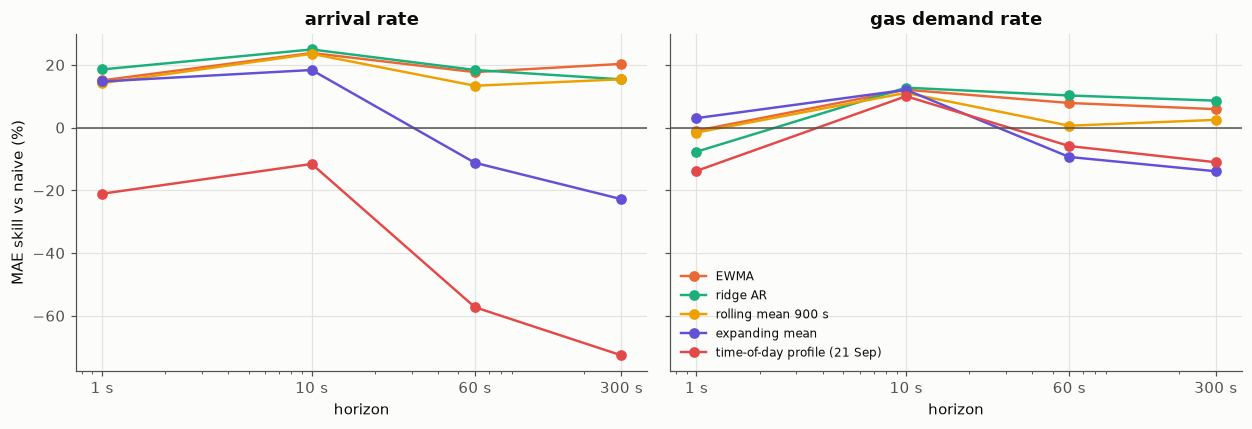

In [5]:
comp = pd.read_csv(EV / "model_comparison_F.csv")
label = {"persistence_interval": "naive", "ewma": "EWMA", "ridge_ar": "ridge AR", "rolling_mean_900": "rolling mean 900 s",
         "expanding_mean": "expanding mean", "tod_profile_0921": "time-of-day profile (21 Sep)"}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for ax, target in zip(axes, ("arrival_rate", "gas_demand_rate")):
    for m in ("ewma", "ridge_ar", "rolling_mean_900", "expanding_mean", "tod_profile_0921"):
        b = comp[(comp.target == target) & (comp.model == m)].sort_values("horizon_s")
        ax.plot(b.horizon_s, b.skill_mae_vs_persistence * 100, marker="o", color=COLORS[m], label=label[m])
    ax.axhline(0, color=fc.TEXT2, lw=1)
    ax.set(xscale="log", xticks=[1, 10, 60, 300], xticklabels=["1 s", "10 s", "60 s", "300 s"], xlabel="horizon", title=target.replace("_", " "))
axes[0].set_ylabel("MAE skill vs naive (%)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

- **Arrival rate.** All smoothers beat naive by about 15-25% at every horizon, and differ from each other by only a
  few percent.
- **Time-of-day profile.** Using the value at the same UTC time on 21 Sep is far worse than naive: a 3-week-old
  level does not transfer.
- **Gas demand.** Every model sits within about ±12% of naive, and none is significant.

## 3. Actual vs predicted

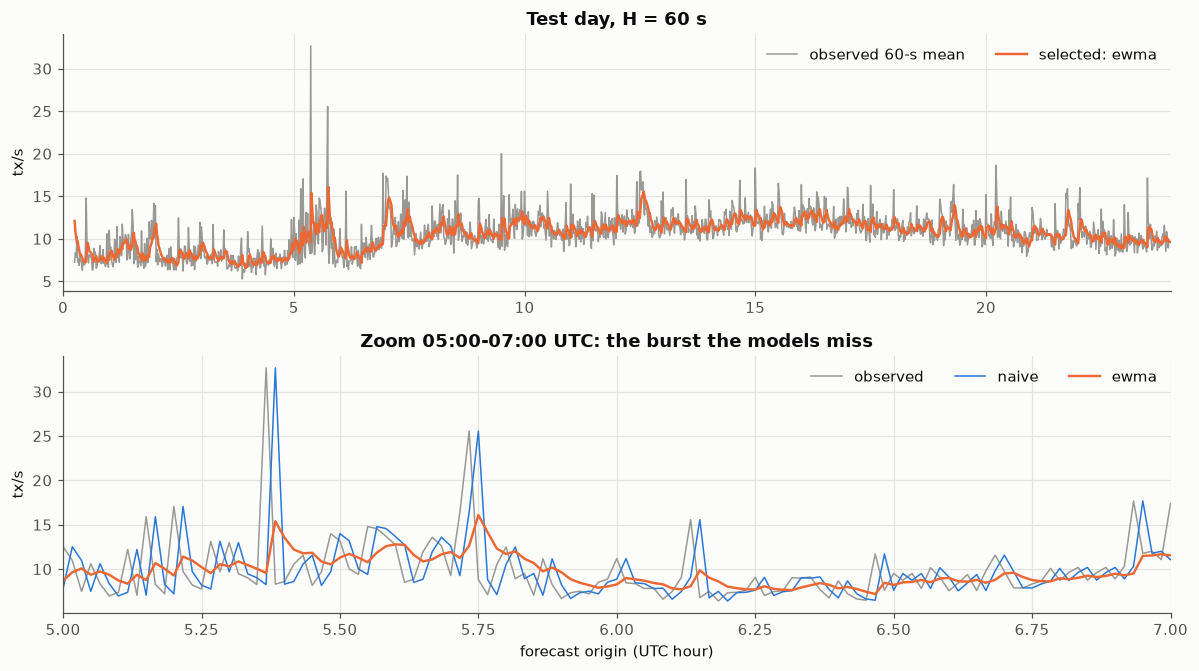

In [6]:
f = load("arrival_rate", 60); m = SEL[("arrival_rate", 60)]; h = f.origin_s / 3600
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
axes[0].plot(h, f.y_observed, color="#9a9893", lw=1, label="observed 60-s mean")
axes[0].plot(h, f[f"yhat_{m}"], color=COLORS[m], lw=1.6, label=f"selected: {m}")
z = (h >= 5) & (h <= 7)
axes[1].plot(h[z], f.y_observed[z], color="#9a9893", lw=1, label="observed")
axes[1].plot(h[z], f.yhat_persistence_interval[z], color=COLORS["persistence_interval"], lw=1, label="naive")
axes[1].plot(h[z], f[f"yhat_{m}"][z], color=COLORS[m], lw=1.6, label=m)
axes[0].set(xlim=(0, 24), ylabel="tx/s", title="Test day, H = 60 s")
axes[1].set(xlim=(5, 7), ylabel="tx/s", xlabel="forecast origin (UTC hour)", title="Zoom 05:00-07:00 UTC: the burst the models miss")
for ax in axes: ax.legend(loc="upper right", ncol=3)
plt.tight_layout(); plt.show()

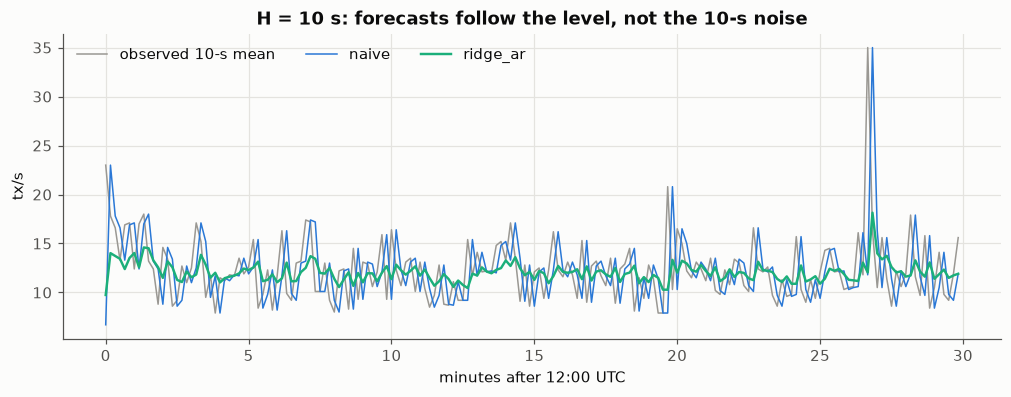

In [7]:
f10 = load("arrival_rate", 10); m10 = SEL[("arrival_rate", 10)]
z = (f10.origin_s >= 43_200) & (f10.origin_s < 45_000); mins = (f10.origin_s[z] - 43_200) / 60
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(mins, f10.y_observed[z], color="#9a9893", lw=1, label="observed 10-s mean")
ax.plot(mins, f10.yhat_persistence_interval[z], color=COLORS["persistence_interval"], lw=1, label="naive")
ax.plot(mins, f10[f"yhat_{m10}"][z], color=COLORS[m10], lw=1.6, label=m10)
ax.set(xlabel="minutes after 12:00 UTC", ylabel="tx/s", title="H = 10 s: forecasts follow the level, not the 10-s noise")
ax.legend(ncol=3); plt.show()

## 4. Residual analysis (selected model, arrival rate)

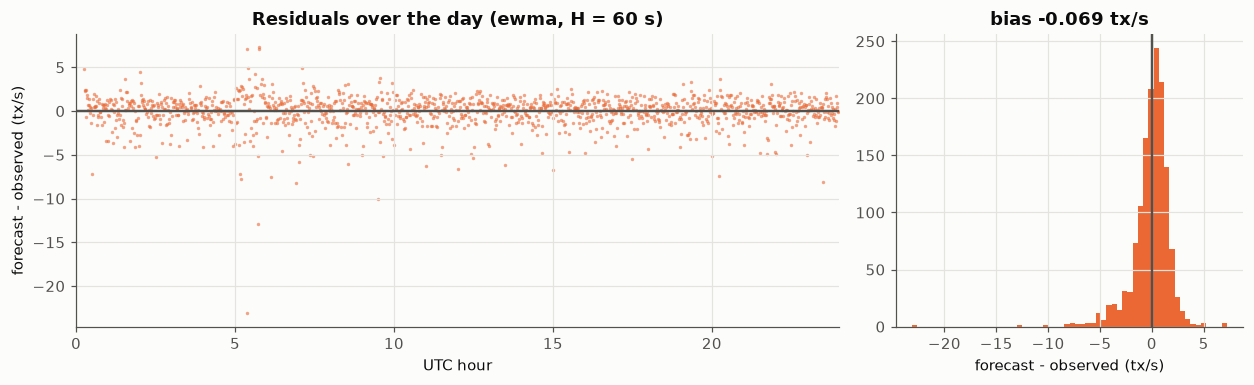

,target,horizon_s,model,residual_mean,residual_sd,residual_acf_lag1,share_abs_error_gt_2sd,largest_under_forecast,largest_under_forecast_at_utc
0,arrival_rate,1,ridge_ar,0.02999,7.766,0.1105,0.0153,-684.8,2026-10-12 05:22:25+00:00
1,arrival_rate,10,ridge_ar,0.003351,3.615,-0.1734,0.02175,-140.5,2026-10-12 05:22:20+00:00
2,arrival_rate,60,ewma,-0.06857,1.833,0.006821,0.05193,-23.12,2026-10-12 05:22:00+00:00
3,arrival_rate,300,ewma,-0.05801,1.258,-0.1161,0.04912,-5.461,2026-10-12 07:00:00+00:00
4,gas_demand_rate,1,rolling_mean_60,-0.0002987,68.95,0.4497,0.001848,"-12,663",2026-10-12 05:22:25+00:00
5,gas_demand_rate,10,ewma,-0.002423,30.17,-0.0209,0.004211,-2240,2026-10-12 05:22:20+00:00
6,gas_demand_rate,60,rolling_mean_900,-0.001557,12.68,0.1219,0.01895,-373.3,2026-10-12 05:22:00+00:00
7,gas_demand_rate,300,ewma,0.01982,6.68,-0.1479,0.02456,-74.48,2026-10-12 05:20:00+00:00


In [8]:
e = f[f"yhat_{m}"] - f.y_observed
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].scatter(h, e, s=5, color=COLORS[m], alpha=.6, linewidths=0); axes[0].axhline(0, color=fc.TEXT2)
axes[0].set(xlim=(0, 24), xlabel="UTC hour", ylabel="forecast - observed (tx/s)", title=f"Residuals over the day ({m}, H = 60 s)")
axes[1].hist(e, bins=60, color=COLORS[m]); axes[1].axvline(0, color=fc.TEXT2)
axes[1].set(xlabel="forecast - observed (tx/s)", title=f"bias {e.mean():+.3f} tx/s")
plt.tight_layout(); plt.show()
pd.read_csv(EV / "residual_diagnostics.csv")[["target", "horizon_s", "model", "residual_mean", "residual_sd", "residual_acf_lag1",
                                              "share_abs_error_gt_2sd", "largest_under_forecast", "largest_under_forecast_at_utc"]]

- **Bias.** Negligible for the arrival rate (-0.07 to +0.03 tx/s).
- **Largest under-forecast.** At every arrival horizon up to 60 s it occurs at **05:22 UTC**: the 817-tx second.
  The smoother then decays slowly, so over-forecasts follow.
- **Gas residuals.** Their sd (12.7 Mgas/s at H = 60) dwarfs the MAE (1.6), so a few bursts dominate.

## 5. Where the forecasts fail: by hour and by load regime

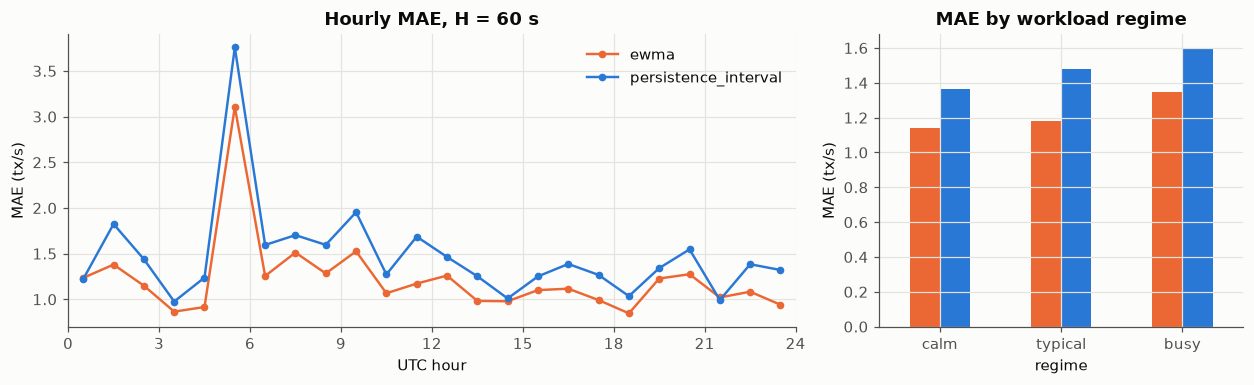

hours where the selected model beats naive: 22 of 24


In [9]:
hourly = pd.read_csv(EV / "error_by_utc_hour_F.csv")
x = hourly[(hourly.target == "arrival_rate") & (hourly.horizon_s == 60)].pivot(index="utc_hour", columns="model", values="mae")
reg = pd.read_csv(EV / "error_by_regime_F.csv")
r = reg[(reg.target == "arrival_rate") & (reg.horizon_s == 60) & reg.model.isin([m, "persistence_interval"])].pivot(index="regime", columns="model", values="mae").loc[["calm", "typical", "busy"]]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [2, 1]})
for col in x.columns:
    axes[0].plot(x.index + .5, x[col], marker="o", ms=4, color=COLORS[col], label=col)
axes[0].set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="UTC hour", ylabel="MAE (tx/s)", title="Hourly MAE, H = 60 s"); axes[0].legend()
r.plot.bar(ax=axes[1], color=[COLORS[c] for c in r.columns], rot=0, legend=False)
axes[1].set(ylabel="MAE (tx/s)", title="MAE by workload regime")
plt.tight_layout(); plt.show()
print("hours where the selected model beats naive:", int((x[m] < x["persistence_interval"]).sum()), "of 24")

## 6. The gas target fails out of sample

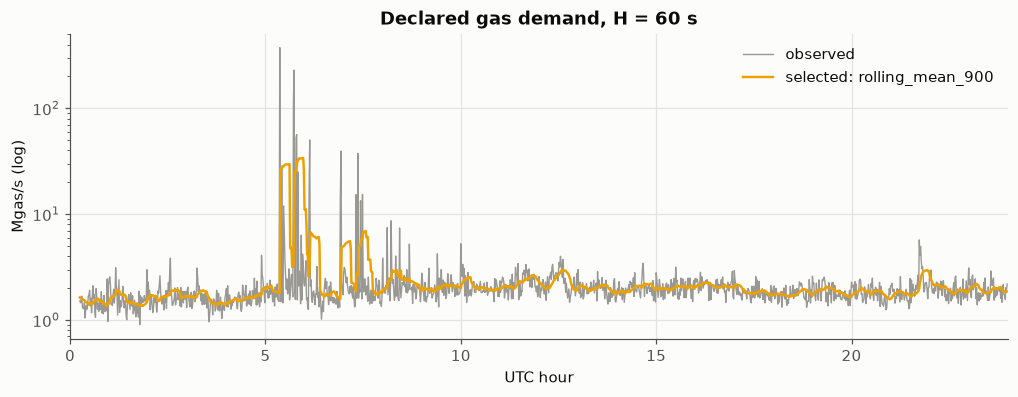

,target,horizon_s,selected,mae_V,mae_F,relative_change_F_vs_V,selected_rank_on_F_among_selectable,n_selectable,regret_vs_best_F_mae
0,arrival_rate,1,ridge_ar,4.78,4.064,-0.1498,1,10,0
1,arrival_rate,10,ridge_ar,2.323,2.195,-0.05532,1,10,0
2,arrival_rate,60,ewma,1.32,1.22,-0.07548,2,7,0.01018
3,arrival_rate,300,ewma,0.8247,0.9399,0.1398,1,6,0
4,gas_demand_rate,1,rolling_mean_60,1.962,2.811,0.4325,6,10,0.1787
5,gas_demand_rate,10,ewma,0.7688,1.971,1.564,2,10,0.01454
6,gas_demand_rate,60,rolling_mean_900,0.3641,1.615,3.436,4,7,0.1566
7,gas_demand_rate,300,ewma,0.2143,1.357,5.332,2,6,0.03914


In [10]:
g = load("gas_demand_rate", 60); gm = SEL[("gas_demand_rate", 60)]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(g.origin_s / 3600, g.y_observed / 1e6, color="#9a9893", lw=.9, label="observed")
ax.plot(g.origin_s / 3600, g[f"yhat_{gm}"] / 1e6, color=fc.SERIES[3], lw=1.6, label=f"selected: {gm}")
ax.set(yscale="log", xlim=(0, 24), xlabel="UTC hour", ylabel="Mgas/s (log)", title="Declared gas demand, H = 60 s"); ax.legend()
plt.show()
pd.read_csv(EV / "validation_vs_test_stability.csv")

The arrival-rate models are **stable**: the test MAE is within -15% to +14% of the validation MAE, and the selected
model ranks 1st or 2nd on the test day. The gas models are **not stable**: test MAE is 1.4-6.3x the validation MAE.

---

## 7. From forecast to Fabric decision

The intended chain:

| Stage | Status | Evidence |
|---|---|---|
| A. Historical Ethereum workload analysis | **COMPLETED** | notebooks 01-03 |
| B. Offline workload forecasting | **COMPLETED (offline)** | notebook 04, P2 + FB-FC-v1 |
| C. Forecast-driven workload replay into Fabric | **DESIGNED, offline artifacts only** | Caliper `replay-rate` schedules in `data/processed/flashbots_ms/windows/` (A = 1:1 replay, BO = oracle per-minute rate, BF = EWMA-forecast rate); `p4_replay/` is LIVE_UNTESTED |
| D. Predictive configuration control in Fabric | **NOT ESTABLISHED** | controllers run in offline shadow/recording replay only |

**The mapping.** Ethereum transactions are never sent to Fabric. Only the **arrival timing** (or per-interval rate)
is reused, to pace synthetic Fabric invocations. Content, sender, gas, fees and key conflicts are not mapped.

### Would a better forecast change the configuration decision?
The project's measured batching law gives the p95 latency as W + c, with batching wait
W = min((B - 1) / rate, 2 s) for block size B (MaxMessageCount) and a 2-s batch timeout. The plot below is plain
arithmetic on that law.

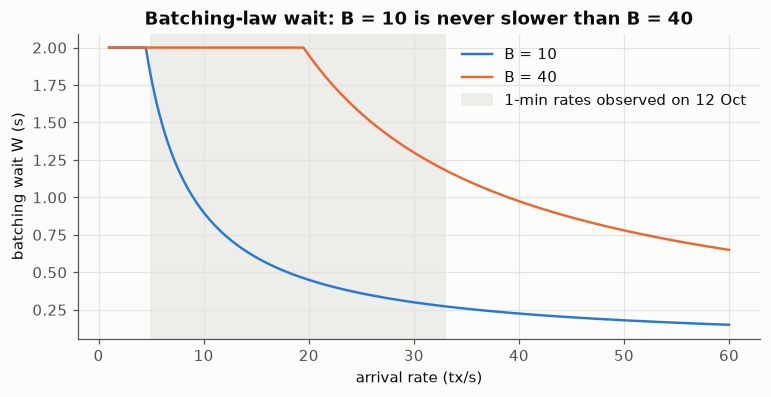

In [11]:
rate = np.linspace(1, 60, 600)
fig, ax = plt.subplots(figsize=(8, 3.6))
for B, colr in ((10, fc.SERIES[0]), (40, fc.SERIES[1])):
    ax.plot(rate, np.minimum((B - 1) / rate, 2.0), color=colr, label=f"B = {B}")
ax.axvspan(5, 33, color="#e4e3df", alpha=.6, label="1-min rates observed on 12 Oct")
ax.set(xlabel="arrival rate (tx/s)", ylabel="batching wait W (s)", title="Batching-law wait: B = 10 is never slower than B = 40"); ax.legend()
plt.show()

In [12]:
voi = json.loads((ROOT / "experiments/results/flashbots_horizon_benchmark_v2/voi/voi_F_summary.json").read_text(encoding="utf-8"))
print("law:", voi["law"])
pd.DataFrame({f"H = {H} s ({v['selected_model']})": {k: v["all_intervals"][k] for k in
              ("static_B10", "static_B40", "oracle_by_interval", "oracle_headroom_over_best_static_s", "forecast_policy",
               "regret_vs_best_static_s", "selection_errors", "share_volume_oracle_chooses_B10")}
              for H, v in voi["horizons"].items()})

law: p95 = W + c; W = min((B-1)/rate, 2 s); c = +25 ms count-cut, -60 ms timer-cut, -24 ms boundary


,H = 60 s (ewma),H = 10 s (rolling_mean_300)
static_B10,0.8755,0.875
static_B40,1.938,1.921
oracle_by_interval,0.8755,0.875
oracle_headroom_over_best_static_s,0,0
forecast_policy,0.8755,0.875
regret_vs_best_static_s,0,0
selection_errors,0,0
share_volume_oracle_chooses_B10,1,1


**Result (stored VOI analysis on the test day):**
- An oracle that knows the future rate achieves the same volume-weighted p95, 0.876 s, as **static B = 10**. The
  **headroom is 0.0 s**.
- The forecast policy also achieves 0.876 s, with 0 selection errors.
- Under this law, B = 10's batching wait is never longer than B = 40's, and the oracle picks B = 10 for 100% of
  traffic.

So for this workload and the {10, 40} menu, **no forecast, however accurate, can improve the decision**.

## Conclusions
1. **Arrival-rate forecasting works offline, modestly.** Simple smoothing (EWMA) beats naive by about 18% at
   H = 60 s on an unseen day. Learned models add little. Bursts are not anticipated.
2. **Gas demand is not forecastable** beyond naive and is not a Fabric quantity.
3. **No demonstrated decision value.** Under the measured batching law and the current configuration menu, static
   B = 10 is already optimal, so forecasting cannot improve the configuration decision.
4. **What would change this.** A configuration menu and objective with a genuine load-dependent trade-off, and a
   live, repeated-run comparison of static, reactive and predictive arms on the Fabric testbed. That work is outside
   this folder and was not run.

**Limitations:**
- only two days, and 12 Oct was already seen by P2;
- public mempool only;
- point forecasts only;
- conclusions hold for the measured days.

See `Flashbots/README.md` and `Flashbots/FABRIC_CONNECTION.md`.